# Lab 7: K-Means Clustering
**Name:** Harshika Soni  
**Reg:** 2427010123  
**Sec:** C

## Objective
Apply the K-Means clustering algorithm to an unlabeled dataset, choose a suitable number of clusters using the elbow method and silhouette score, visualize the clusters, and interpret the cluster centroids.

**Dataset:** Iris flower measurements (the same data as the Kaggle *Iris Species* dataset, loaded here through scikit-learn so the notebook runs anywhere without a download).

## 1. Import libraries
Pandas holds the data. Matplotlib and Seaborn draw the graphs. Scikit-learn provides scaling, K-Means, PCA, and the evaluation metrics.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

sns.set_theme(style="whitegrid")

## 2. Load and inspect the data
The dataset has 150 flowers with four measurements each. It also stores the true species, but K-Means is **unsupervised**, so we will *not* give the species to the algorithm. We keep them aside only to check the result at the end.

In [2]:
iris = load_iris(as_frame=True)
df = iris.data.copy()
df.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
true_species = pd.Series(iris.target_names[iris.target], name="species")

print("Dataset shape (rows, columns):", df.shape)
print("\nMissing values:")
print(df.isnull().sum())
df.head()

Dataset shape (rows, columns): (150, 4)

Missing values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
dtype: int64


,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [3]:
# Summary statistics of the four measurements (in cm)
df.describe().round(2)

,sepal_length,sepal_width,petal_length,petal_width
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


## 3. Scale the features
K-Means groups points by **distance**, so a feature with a larger range would dominate the result. `StandardScaler` rewrites every feature to have mean 0 and standard deviation 1, so all four measurements count equally.

In [4]:
features = list(df.columns)
scaler = StandardScaler()
X = scaler.fit_transform(df)

print("Mean after scaling:", X.mean(axis=0).round(2))
print("Std after scaling: ", X.std(axis=0).round(2))

Mean after scaling: [-0. -0. -0. -0.]
Std after scaling:  [1. 1. 1. 1.]


## 4. Choose the number of clusters (k)
K-Means needs `k` in advance. Two common guides:

* **Inertia (elbow method):** the sum of squared distances from each point to its cluster centre. It always falls as `k` grows, so we look for the *elbow* where the drop becomes small.
* **Silhouette score:** compares how close a point is to its own cluster against the nearest other cluster. It ranges from -1 to 1, and higher is better.

In [5]:
k_values = range(2, 11)
inertias, silhouettes = [], []

for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = model.fit_predict(X)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X, labels))

k_results = pd.DataFrame({
    "k": list(k_values),
    "Inertia": inertias,
    "Silhouette": silhouettes
})
k_results.round(3)

,k,Inertia,Silhouette
0,2,222.362,0.582
1,3,139.820,0.460
2,4,114.093,0.387
3,5,90.928,0.346
4,6,81.544,0.317
5,7,72.631,0.320
6,8,62.541,0.339
7,9,55.119,0.342
8,10,47.391,0.352


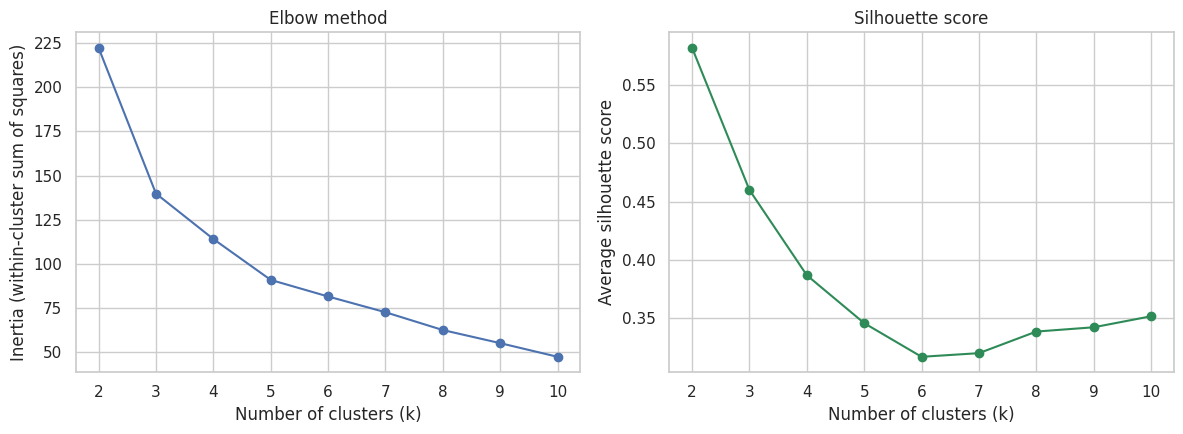

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(k_results["k"], k_results["Inertia"], marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia (within-cluster sum of squares)")

axes[1].plot(k_results["k"], k_results["Silhouette"], marker="o", color="seagreen")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Average silhouette score")

for ax in axes:
    ax.set_xticks(list(k_values))
plt.tight_layout()
plt.show()

**Reading the graphs:** The inertia curve bends sharply up to k = 3 and then flattens, so the elbow is around 3. The silhouette score is highest at k = 2 because two of the groups overlap, but k = 3 still has a reasonable score (about 0.46) and matches the three groups we expect in flower data. We therefore use **k = 3**.

## 5. Fit the final K-Means model (k = 3)
`n_init=10` runs the algorithm from 10 different random starting centres and keeps the best result, because K-Means can get stuck in a poor solution from one unlucky start.

In [7]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
df["cluster"] = kmeans.fit_predict(X)

print("Final inertia:", round(kmeans.inertia_, 2))
print("Iterations until convergence:", kmeans.n_iter_)
print("Silhouette score:", round(silhouette_score(X, df["cluster"]), 3))
print("\nCluster sizes:")
print(df["cluster"].value_counts().sort_index())

Final inertia: 139.82
Iterations until convergence: 4
Silhouette score: 0.46

Cluster sizes:
cluster
0    53
1    50
2    47
Name: count, dtype: int64


## 6. Interpret the cluster centres
The centres are computed on scaled data, so we convert them back to centimetres to read them easily.

In [8]:
centers_cm = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=features
)
centers_cm.index.name = "cluster"
centers_cm.round(2)

,sepal_length,sepal_width,petal_length,petal_width
cluster,,,,
0,5.80,2.67,4.37,1.41
1,5.01,3.43,1.46,0.25
2,6.78,3.10,5.51,1.97


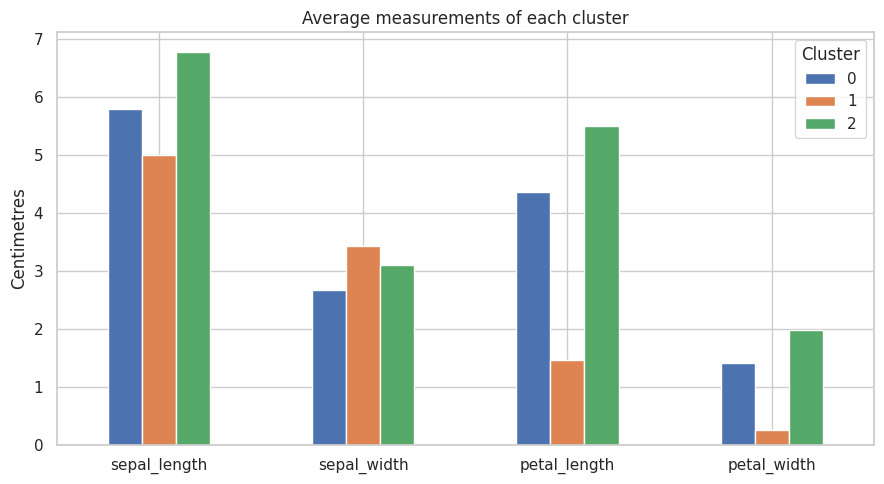

In [9]:
# Compare the average measurement of each cluster side by side
centers_cm.T.plot(kind="bar", figsize=(9, 5))
plt.title("Average measurements of each cluster")
plt.ylabel("Centimetres")
plt.xticks(rotation=0)
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

## 7. Visualize the clusters
Four dimensions cannot be drawn directly. **PCA** squeezes the four features into two new axes while keeping as much of the spread as possible, so we can see the clusters on a flat plot.

Variance explained by the two components: [73.  22.9] %
Total: 95.8 %


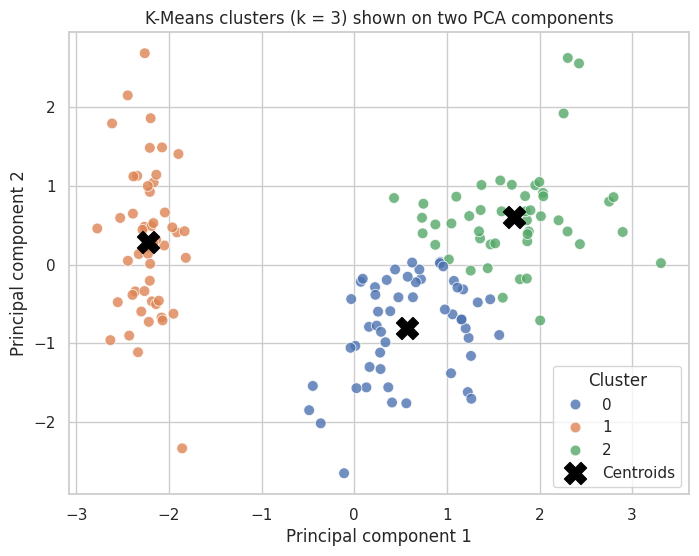

In [10]:
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X)
centers_2d = pca.transform(kmeans.cluster_centers_)

print("Variance explained by the two components:",
      (pca.explained_variance_ratio_ * 100).round(1), "%")
print("Total:", round(pca.explained_variance_ratio_.sum() * 100, 1), "%")

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=df["cluster"],
                palette="deep", s=60, alpha=0.8)
plt.scatter(centers_2d[:, 0], centers_2d[:, 1], c="black", marker="X",
            s=250, label="Centroids")
plt.title("K-Means clusters (k = 3) shown on two PCA components")
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.legend(title="Cluster")
plt.show()

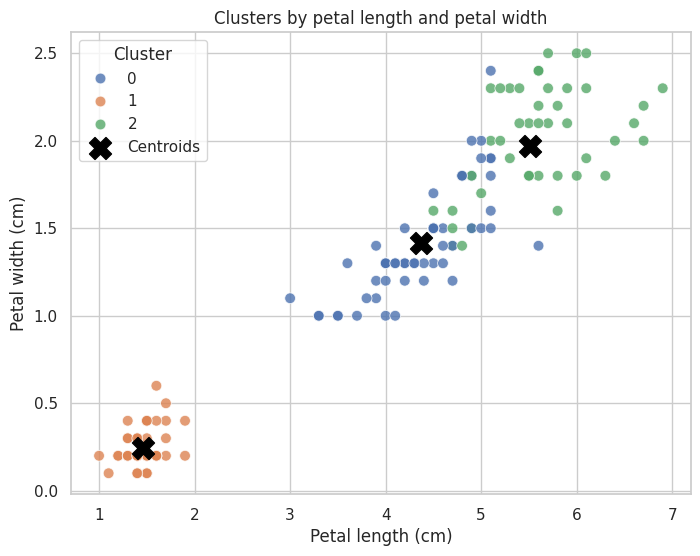

In [11]:
# The two most informative original features, with the centroids marked
centers_plot = centers_cm[["petal_length", "petal_width"]]

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="petal_length", y="petal_width",
                hue="cluster", palette="deep", s=60, alpha=0.8)
plt.scatter(centers_plot["petal_length"], centers_plot["petal_width"],
            c="black", marker="X", s=250, label="Centroids")
plt.title("Clusters by petal length and petal width")
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.legend(title="Cluster")
plt.show()

## 8. Check the clusters against the real species
Normally clustering has no answer key, but Iris does, so we can see how well the unsupervised result lines up with the true species. The **Adjusted Rand Index (ARI)** measures agreement between two groupings: 1 is a perfect match and 0 is no better than random.

In [12]:
comparison = pd.crosstab(df["cluster"], true_species)
print(comparison)
print("\nAdjusted Rand Index:", round(adjusted_rand_score(true_species, df["cluster"]), 3))

species  setosa  versicolor  virginica
cluster                               
0             0          39         14
1            50           0          0
2             0          11         36

Adjusted Rand Index: 0.62


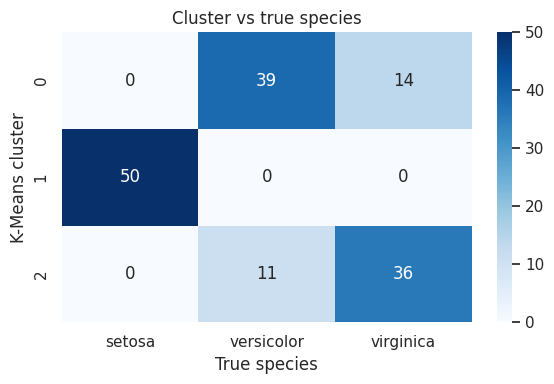

In [13]:
plt.figure(figsize=(6, 4))
sns.heatmap(comparison, annot=True, fmt="d", cmap="Blues")
plt.title("Cluster vs true species")
plt.ylabel("K-Means cluster")
plt.xlabel("True species")
plt.tight_layout()
plt.show()

## 9. Conclusion
* The elbow and silhouette graphs together pointed to **k = 3** clusters.
* One cluster has small petals and is completely separated from the rest, and it matches *setosa* exactly.
* The other two clusters overlap slightly, because *versicolor* and *virginica* have similar measurements, so 25 of the 100 flowers from those two species land in the neighbouring cluster (ARI = 0.62).
* Scaling the features first was important so that no single measurement dominated the distances.
* K-Means never saw the species labels, yet it recovered most of the real structure, which shows that clustering can find meaningful groups in unlabeled data.

**Limitations:** K-Means assumes roughly round clusters of similar size, needs `k` chosen in advance, and is sensitive to outliers and to the starting centres.